In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from pathlib import Path
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

idx = pd.read_csv(PROC / "national_monthly_index.csv")
idx["ym"] = pd.PeriodIndex(idx["ym"], freq="M")
wide = idx.pivot(index="ym", columns="commodity", values="idx_fe")
print(wide.shape)

(126, 5)


In [2]:
SEG = {"A": ("2016-01", "2019-05"), "B": ("2020-05", "2026-06")}
segs = {k: wide.loc[a:b] for k, (a, b) in SEG.items()}

for k, s in segs.items():
    print(f"Segment {k}: {len(s)} months, missing values = {int(s.isna().sum().sum())}")

Segment A: 41 months, missing values = 0
Segment B: 74 months, missing values = 0


In [3]:
def tag(p):
    return "Pre-COVID" if p < pd.Period("2020-03") else ("During-COVID" if p <= pd.Period("2023-05") else "Post-COVID")

frames = []
for k, s in segs.items():
    ls = np.log(s)
    dl = ls.diff()            # computed inside the segment only
    for c in s.columns:
        frames.append(pd.DataFrame({"ym": s.index, "commodity": c, "segment": k,
                                    "log_idx": ls[c].values, "dlog": dl[c].values}))
long = pd.concat(frames, ignore_index=True)
long["period"] = long["ym"].map(tag)
print("Rows:", len(long))

vol = (long.dropna(subset=["dlog"])
           .assign(dlog_pct=lambda x: x["dlog"] * 100)
           .groupby(["commodity", "period"])["dlog_pct"]
           .agg(["count", "mean", "std"]).round(2))
display(vol)
vol.to_csv(TAB / "06_volatility_by_period.csv")

Rows: 575


count  mean    std
commodity                     period                          
Meat (beef, chops with bones) During-COVID     36  0.93   1.00
                              Post-COVID       37  0.31   0.39
                              Pre-COVID        40  0.51   0.71
Meat (chicken, whole)         During-COVID     36  0.77   2.65
                              Post-COVID       37  0.17   1.22
                              Pre-COVID        40  0.18   1.22
Meat (pork)                   During-COVID     36  1.13   2.11
                              Post-COVID       37  0.11   1.47
                              Pre-COVID        40  0.36   0.95
Onions (red)                  During-COVID     36  1.38  19.05
                              Post-COVID       37 -0.92   9.94
                              Pre-COVID        40 -1.33  10.35
Rice (regular, milled)        During-COVID     36  0.17   0.81
                              Post-COVID       37  0.55   3.21
                              Pre-COVID        40  0.11   2.06

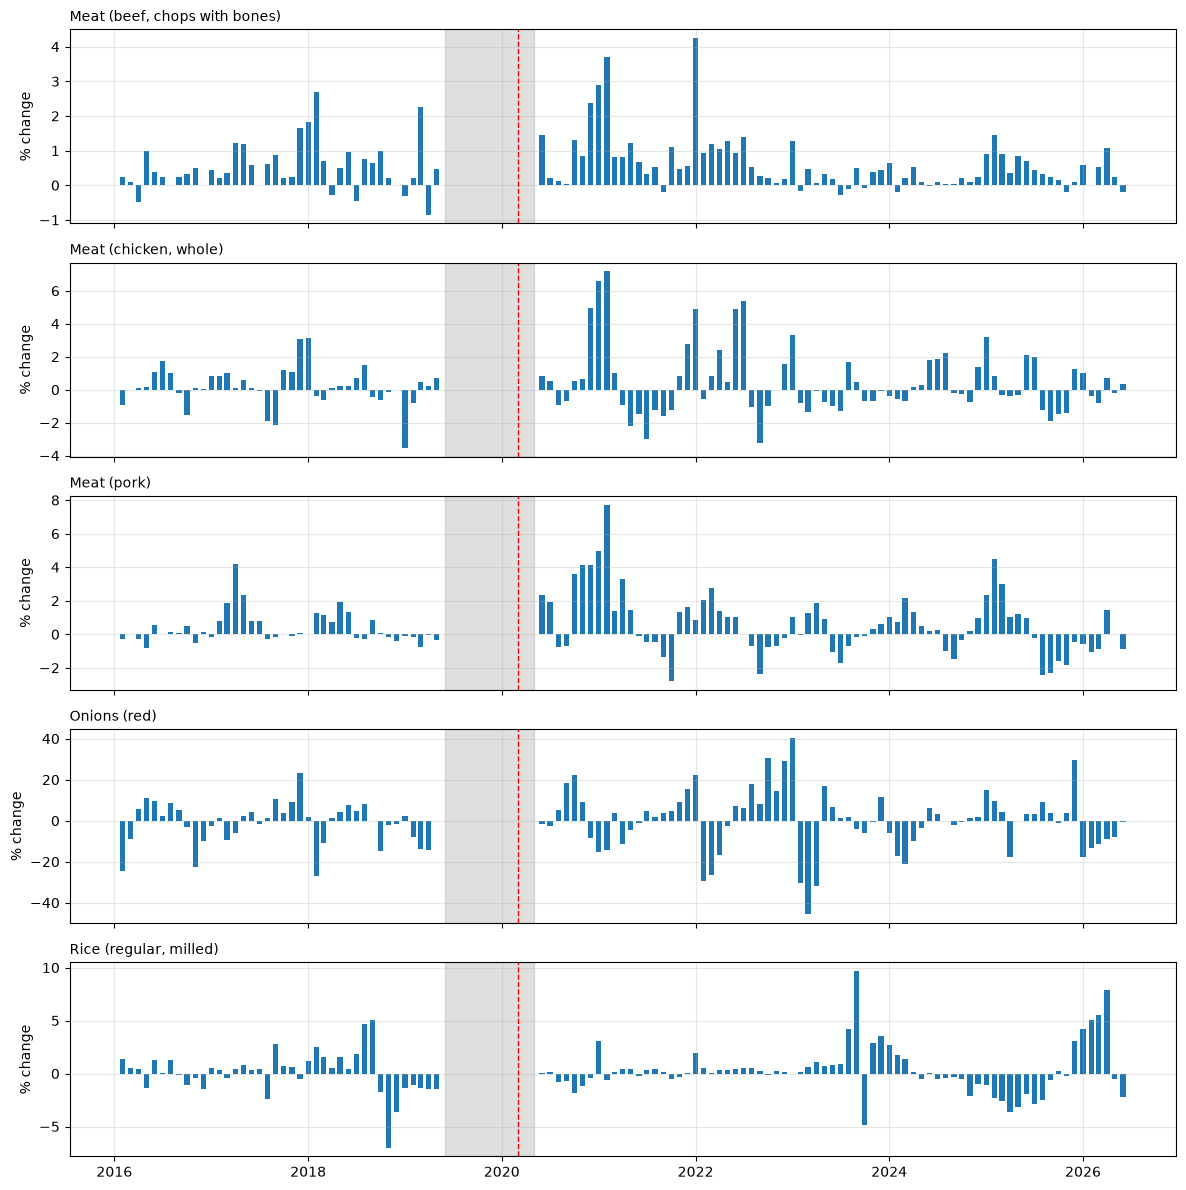

In [4]:
fig, axes = plt.subplots(5, 1, figsize=(12, 12), sharex=True)
for ax, (c, d) in zip(axes, long.dropna(subset=["dlog"]).groupby("commodity")):
    ax.bar(d["ym"].dt.to_timestamp(), d["dlog"] * 100, width=20)
    ax.axvspan(pd.Timestamp("2019-06-01"), pd.Timestamp("2020-04-30"), color="grey", alpha=0.25)
    ax.axvline(pd.Timestamp("2020-03-01"), color="red", ls="--", lw=1)
    ax.set_title(c, loc="left", fontsize=10); ax.set_ylabel("% change"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "06_monthly_log_changes.png", dpi=150)
plt.show()

In [7]:
def run_tests(x):
    x = pd.Series(x).dropna()
    adf_p = adfuller(x, regression="c", autolag="AIC", result_object=False)[1]   # H0: unit root
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        kpss_p = kpss(x, regression="c", nlags="auto", result_object=False)[1]   # H0: stationary
    if adf_p < 0.05 and kpss_p > 0.05:
        verdict = "stationary"
    elif adf_p >= 0.05 and kpss_p <= 0.05:
        verdict = "non-stationary"
    else:
        verdict = "inconclusive"
    return round(adf_p, 3), round(kpss_p, 3), verdict

rows = []
for k, s in segs.items():
    ls = np.log(s)
    for c in s.columns:
        for label, x in [("log level", ls[c]), ("first difference", ls[c].diff())]:
            a, kp, v = run_tests(x)
            rows.append({"commodity": c, "segment": k, "series": label,
                         "n": int(x.notna().sum()), "adf_p": a, "kpss_p": kp, "verdict": v})

tests = pd.DataFrame(rows)
display(tests)
display(tests.pivot_table(index=["commodity", "segment"], columns="series",
                          values="verdict", aggfunc="first"))
tests.to_csv(TAB / "06_stationarity_tests.csv", index=False)

,commodity,segment,series,n,adf_p,kpss_p,verdict
0,"Meat (beef, chops with bones)",A,log level,41,0.976,0.010,non-stationary
1,"Meat (beef, chops with bones)",A,first difference,40,0.000,0.100,stationary
2,"Meat (chicken, whole)",A,log level,41,0.239,0.010,non-stationary
3,"Meat (chicken, whole)",A,first difference,40,0.001,0.100,stationary
4,Meat (pork),A,log level,41,0.655,0.010,non-stationary
5,Meat (pork),A,first difference,40,0.032,0.100,stationary
6,Onions (red),A,log level,41,0.150,0.100,inconclusive
7,Onions (red),A,first difference,40,0.000,0.100,stationary
8,"Rice (regular, milled)",A,log level,41,0.361,0.026,non-stationary
9,"Rice (regular, milled)",A,first difference,40,0.002,0.100,stationary


series                                first difference       log level
commodity                     segment                                 
Meat (beef, chops with bones) A             stationary  non-stationary
                              B         non-stationary  non-stationary
Meat (chicken, whole)         A             stationary  non-stationary
                              B             stationary  non-stationary
Meat (pork)                   A             stationary  non-stationary
                              B             stationary  non-stationary
Onions (red)                  A             stationary    inconclusive
                              B             stationary      stationary
Rice (regular, milled)        A             stationary  non-stationary
                              B             stationary  non-stationary

In [8]:
long["ym"] = long["ym"].astype(str)
long.to_csv(PROC / "log_index_segments.csv", index=False)
print(long.shape)

(575, 6)
